In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.metrics import confusion_matrix

from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression

In [4]:
data = pd.read_csv("netflix_titles.csv", sep = ',')
data.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,TV Show,3%,NaN,"João Miguel, Bianca Comparato, Michel Gomes, R...",Brazil,"August 14, 2020",2020,TV-MA,4 Seasons,"International TV Shows, TV Dramas, TV Sci-Fi &...",In a future where the elite inhabit an island ...
1,s2,Movie,7:19,Jorge Michel Grau,"Demián Bichir, Héctor Bonilla, Oscar Serrano, ...",Mexico,"December 23, 2016",2016,TV-MA,93 min,"Dramas, International Movies",After a devastating earthquake hits Mexico Cit...
2,s3,Movie,23:59,Gilbert Chan,"Tedd Chan, Stella Chung, Henley Hii, Lawrence ...",Singapore,"December 20, 2018",2011,R,78 min,"Horror Movies, International Movies","When an army recruit is found dead, his fellow..."
3,s4,Movie,9,Shane Acker,"Elijah Wood, John C. Reilly, Jennifer Connelly...",United States,"November 16, 2017",2009,PG-13,80 min,"Action & Adventure, Independent Movies, Sci-Fi...","In a postapocalyptic world, rag-doll robots hi..."
4,s5,Movie,21,Robert Luketic,"Jim Sturgess, Kevin Spacey, Kate Bosworth, Aar...",United States,"January 1, 2020",2008,PG-13,123 min,Dramas,A brilliant group of students become card-coun...


In [11]:
continent_mapping = {
    'USA': 'N.America',
'Jamaica': 'N.America',
'Mexico': 'N.America',
    'United States': 'N.America',
    'Canada': 'N.America',
    
    'Brazil': 'S. America',
'Argentina': 'S. America',
'Colombia': 'S. America',
'Peru': 'S. America',

    
    'China': 'Asia',
    'India': 'Asia',
'Japan': 'Asia',
'Malaysia': 'Asia',
'Singapore': 'Asia',
'South Korea': 'Asia',
'Taiwan': 'Asia',
'Thailand': 'Asia',
'Vietnam': 'Asia',
    
    'Germany': 'Europe',
'Denmark': 'Europe',
'France': 'Europe',
'Greece': 'Europe',
'Italy': 'Europe',
'Netherlands': 'Europe',
'Norway': 'Europe',
'Russia': 'Europe',
'Turkey': 'Europe',
'Ukraine': 'Europe',
'United Kingdom': 'Europe',
    
'Australia': 'Oceania',
'New Zealand': 'Oceania',
    
 
'Egypt': 'Africa',
'Sudan': 'Africa',
'Tunisia': 'Africa',
'Uganda': 'Africa',
'Zimbabwe': 'Africa',
    
    
}
data['continent'] = data['country'].map(continent_mapping)
continent_counts = data.groupby('continent').size().reset_index(name='Number_of_Movies')

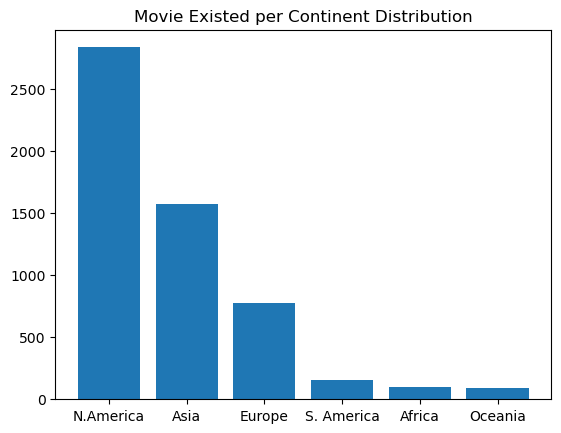

In [13]:

df = pd.DataFrame(data)
continent_count = df['continent'].value_counts()
plt.bar(continent_count.index,continent_count)
plt.title("Movie Existed per Continent Distribution")

plt.show()

In [64]:
data['type']=data['type'].replace({'Movie':0,'TV Show':1})

In [69]:
#data['type'] = data['type'].replace({'TV Show': 0, 'Movie': 1})

label_encoder = LabelEncoder()
data['title_encoded'] = label_encoder.fit_transform(data['title'])
data['cast_encoded'] = label_encoder.fit_transform(data['cast'])

Confusion Matrix:
[[1136  452]
 [ 486  263]]


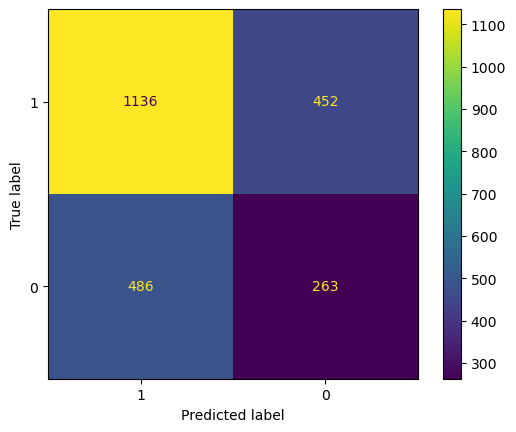

In [70]:
input_column = ['title_encoded','cast_encoded']  # You can add more columns as needed
X = data[input_column]
y = data['type']  # Target variable

# Split Data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1)

# Modeling
classify = DecisionTreeClassifier()

# Train Model
classify = classify.fit(X_train, y_train)

# Prediction / Testing
predict_y = classify.predict(X_test)

# Confusion Matrix
cm = confusion_matrix(y_test, predict_y)
print("Confusion Matrix:")
print(cm)

# Plot Confusion Matrix
cm_plot = metrics.ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=data['type'].unique())
cm_plot.plot()
plt.show()

In [71]:
# Accuracy
accuracy = metrics.accuracy_score(y_test, predict_y)
print("Accuracy:", accuracy)

# Precision
precision = metrics.precision_score(y_test, predict_y)
print("Precision:", precision)

# Sensitivity
sensitivity = metrics.recall_score(y_test, predict_y)
print("Sensitivity (Recall):", sensitivity)

# Specificity
tn, fp, fn, tp = cm.ravel()
specificity = tn / (tn + fp)
print("Specificity:", specificity)


Accuracy: 0.5986307231493367
Precision: 0.3678321678321678
Sensitivity (Recall): 0.35113484646194926
Specificity: 0.7153652392947103


In [51]:
print(pd.Series(predict_y).value_counts())


0    2337
Name: count, dtype: int64


In [52]:
print(data['type'].value_counts())


type
0    5377
1    2410
Name: count, dtype: int64


Confusion Matrix:
[[1588    0]
 [ 749    0]]


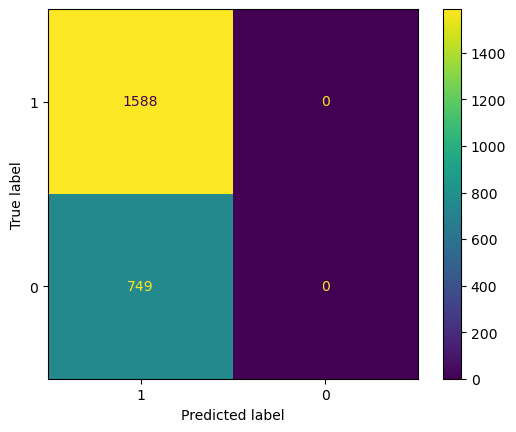

In [74]:

# Assuming 'title_encoded' is a suitable numerical feature
input_column = ['title_encoded']
X = data[input_column]
y = data['type']

# Split Data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1)

# Modeling
classify = LogisticRegression()

# Train Model
classify = classify.fit(X_train, y_train)

# Prediction / Testing
predict_y = classify.predict(X_test)

# Confusion Matrix
cm = confusion_matrix(y_test, predict_y)
print("Confusion Matrix:")
print(cm)

# Plot Confusion Matrix
cm_plot = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=data['type'].unique())
cm_plot.plot()
plt.show()


In [73]:
# Accuracy
accuracy = metrics.accuracy_score(y_test, predict_y)
print("Accuracy:", accuracy)

# Precision
precision = metrics.precision_score(y_test, predict_y)
print("Precision:", precision)

# Sensitivity
sensitivity = metrics.recall_score(y_test, predict_y)
print("Sensitivity (Recall):", sensitivity)

# Specificity
tn, fp, fn, tp = cm.ravel()
specificity = tn / (tn + fp)
print("Specificity:", specificity)


Accuracy: 0.6795036371416345
Precision: 0.0
Sensitivity (Recall): 0.0
Specificity: 1.0


C:\Users\Acer\.conda\envs\Tan2\lib\site-packages\sklearn\metrics\_classification.py:1469: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
